# MG628 Midterm Review Lab: Worked Solutions

This review walks through every topic on the midterm, one worked problem at a time. For each task you'll see:

1. **The question**
2. **How to solve it:** the reasoning, the formula, the steps, and the Excel equivalent
3. **The solution** in Python, with its output
4. **The interpretation:** what the result means for the decision

**How to study with it:** read the question and try it yourself first (on paper, in Excel, or in a new code cell), then read *How to solve it* and compare.

**Running it in Google Colab:** choose **Runtime → Run all**, or run the cells one at a time from the top with **Shift + Enter**. The practice dataset loads directly from the MG628 GitHub, so you don't need to upload anything. To experiment, use **File → Save a copy in Drive** first so your changes are kept.

**Covers:** analytics foundations and the newsvendor model, data sources and systems, process metrics, data cleaning, descriptive statistics, visualization, and decisions under uncertainty (EMV, EVPI, Bayes' rule, expected utility, Monte Carlo). Inferential statistics is not on the midterm and is not covered here.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.float_format', '{:,.2f}'.format)

### Load the data from the MG628 GitHub

The practice dataset lives on the course GitHub, so nothing needs to be uploaded to Colab. Run the next cell; it reads the CSV straight from GitHub.

In [2]:
# Practice dataset on the MG628 GitHub (raw file link)
DATA_URL = "https://raw.githubusercontent.com/GITHUB_USER/GITHUB_REPO/main/clinic_visits.csv"

df_check = pd.read_csv(DATA_URL)
print(f"Loaded {len(df_check):,} rows and {df_check.shape[1]} columns from GitHub")

Loaded 1,205 rows and 10 columns from GitHub


## Section 1: Analytics foundations and decision models

**1.1 Types of analytics.** Label each question as descriptive, diagnostic, predictive, or prescriptive:

- (a) How many patients did each clinic see last month?
- (b) Why did Eastview's wait times rise in the summer?
- (c) How many patients will Downtown see next January?
- (d) How many nurses should each clinic schedule per shift to minimize cost while keeping waits under 30 minutes?

**1.1 Answers:** (a) descriptive, (b) diagnostic, (c) predictive, (d) prescriptive.

**1.2 Newsvendor.** A weekend market stand sells fresh juice for \$6.00 a bottle. Each bottle costs \$2.25 to make, and unsold bottles are sold to a café for \$0.50 at closing. Daily demand is roughly normal, with mean 150 bottles and standard deviation 30.

Tasks:
1. Calculate the underage cost, the overage cost, and the critical ratio.
2. Find the order quantity that matches the critical ratio. Hint: `stats.norm.ppf(ratio, mean, sd)` [Excel: `NORM.INV(ratio, mean, sd)`].
3. Interpret: why is the best quantity above average demand?

### How to solve it

**Idea.** The newsvendor model balances two mistakes: making too few (you lose the profit on every sale you miss) and making too many (you lose money on every unsold unit).

**Step 1: Underage cost (Cu)**, the profit lost per unit short = price − cost = 6.00 − 2.25 = **\$3.75**.

**Step 2: Overage cost (Co)**, the loss per unit left over = cost − salvage = 2.25 − 0.50 = **\$1.75**.

**Step 3: Critical ratio** = Cu ÷ (Cu + Co) = 3.75 ÷ 5.50 = **0.682**. This is the target probability that demand will *not* exceed what you make.

**Step 4: Order quantity.** Find the demand level with 68.2% of the distribution below it. For a normal distribution that is mean + z × SD, where z is the 0.682 quantile (about 0.47): 150 + 0.47 × 30 ≈ **164**.

**Excel:** `=NORM.INV(0.682, 150, 30)`.

**Common mistakes:** using price instead of profit for Cu; forgetting the salvage value in Co; reading the ratio as "make 68% of demand."

In [3]:
# 1.2 Newsvendor
price, cost, salvage = 6.00, 2.25, 0.50
mu, sd = 150, 30

cu = price - cost          # underage cost: profit lost per bottle short
co = cost - salvage        # overage cost: loss per unsold bottle
cr = cu / (cu + co)
q = stats.norm.ppf(cr, mu, sd)
print(f"Underage cost = ${cu:.2f}, overage cost = ${co:.2f}")
print(f"Critical ratio = {cr:.4f}")
print(f"Optimal order = {q:.1f}, so make {round(q)} bottles")

Underage cost = $3.75, overage cost = $1.75
Critical ratio = 0.6818
Optimal order = 164.2, so make 164 bottles


**Interpretation:** Running short costs \$3.75 in lost profit per bottle, while overproducing costs only \$1.75. Because shortages are more expensive, the stand should make more than average demand: about 164 bottles, which covers demand on roughly 68% of days.

**1.3 Break-even (the Goal Seek idea).** A clinic has monthly fixed costs of \$42,000, a variable cost of \$118 per visit, and expects 600 visits a month. What charge per visit makes monthly profit exactly \$0?

Solve it algebraically, then check it by searching for the price numerically (this is what Goal Seek does) [Excel: Data → What-If Analysis → Goal Seek].

### How to solve it

**Idea.** Break-even is the price where revenue exactly covers all costs, so profit = 0.

**Step 1: Write profit as a formula of price (p):** profit = visits × (p − variable cost) − fixed cost = 600 × (p − 118) − 42,000.

**Step 2: Set profit to 0 and solve:** 600 × (p − 118) = 42,000 → p − 118 = 70 → **p = \$188**.

**Step 3: Check numerically.** Goal Seek does the same thing by trial: it keeps changing the price until the profit cell hits 0. In Python, `brentq` searches between two prices for where profit crosses zero.

**Excel:** put the profit formula in a cell, then Data → What-If Analysis → Goal Seek: *Set cell* = profit, *To value* = 0, *By changing cell* = price.

**Reading it:** each visit must cover its own \$118 cost plus a \$70 share of the fixed costs (\$42,000 ÷ 600).

In [4]:
# 1.3 Break-even price
from scipy.optimize import brentq
fixed, var_cost, visits = 42000, 118, 600

profit = lambda p: visits * (p - var_cost) - fixed
algebra = var_cost + fixed / visits
numeric = brentq(profit, var_cost, 1000)     # Goal Seek: find p where profit(p) = 0
print(f"Break-even charge (algebra) = ${algebra:.2f}")
print(f"Break-even charge (numeric search) = ${numeric:.2f}")

Break-even charge (algebra) = $188.00
Break-even charge (numeric search) = $188.00


## Section 2: Data sources and systems (concept check)

Answer in a Markdown cell. These mirror the exam's conceptual questions.

1. Classify each as structured, semi-structured, or unstructured: (a) `clinic_visits.csv`, (b) a JSON response from a scheduling API, (c) scanned referral letters.
2. Which enterprise system would hold each: (a) supplier purchase orders, (b) patient follow-up reminders and outreach campaigns, (c) the general ledger?
3. The clinic chain wants a single place to analyze five years of visits from all four clinics. Should it run reports on the live scheduling database or on a data warehouse? Why?
4. In ETL, which step would standardize clinic names and convert charges to numbers?
5. Give one reason the chain might store free-text patient feedback in a NoSQL document database rather than a relational table.

### Model answers

1. (a) Structured, (b) semi-structured, (c) unstructured.
2. (a) SCM (or ERP purchasing), (b) CRM, (c) ERP.
3. A data warehouse. It integrates historical data from all clinics and is optimized for analysis, so heavy reports don't slow down the live system that runs patient check-ins.
4. Transform.
5. Feedback has no fixed structure (different lengths, optional fields, attachments), and document databases store records with varying attributes without a rigid schema.

## Section 3: Data cleaning

**Scenario.** CareFirst Urgent Care runs four clinics: Downtown, Northside, Eastview, and Harbor. `clinic_visits.csv` holds one row per visit for 2025, but it came straight from the source systems and has problems.

| Column | Meaning |
| --- | --- |
| visit_id | Unique visit ID |
| clinic | Clinic name |
| visit_date | Date of visit |
| checkin_time, seen_time | Time the patient checked in and was seen by a provider (HH:MM) |
| payer | Private, Medicaid, Medicare, or Self-pay |
| charge, cost | Amount billed and cost of the visit (\$) |
| outcome | Resolved, Referred, or Left without being seen |
| satisfaction | Survey score from 1 to 10 |

**3.1** Load the file and inspect it: shape, data types, missing values, and the distinct values of `clinic`, `payer`, and `outcome`. List every problem you can find before fixing anything.

### How to solve it

**Idea.** Never clean blind. Inspect first, list every problem, then fix them one at a time.

**What to run and what each reveals:**
- `df.shape` and `df.info()`: row count and column types. Here `charge` shows as text, not a number, which is a red flag.
- `df.isna().sum()`: blanks per column (payer and charge).
- `value_counts()` on each category column: inconsistent labels appear as extra categories, such as "Down Town" next to "Downtown".
- `sorted(df['satisfaction'].unique())`: reveals 99, which isn't a valid 1 to 10 score. It is a placeholder code (a "sentinel").
- `df.duplicated().sum()`: exact repeat rows.

**Excel:** filter drop-downs on each column show the distinct values; `COUNTBLANK` counts blanks; Conditional Formatting → Duplicate Values highlights repeats.

In [5]:
# 3.1 Load and inspect
df_raw = pd.read_csv(DATA_URL)
print(df_raw.shape)
df_raw.info()
print("\nMissing values:\n", df_raw.isna().sum())
print("\nClinic labels:\n", df_raw['clinic'].value_counts())
print("\nPayer:\n", df_raw['payer'].value_counts(dropna=False))
print("\nOutcome:\n", df_raw['outcome'].value_counts())
print("\nSatisfaction values:", sorted(df_raw['satisfaction'].unique()))
print("Exact duplicate rows:", df_raw.duplicated().sum())

(1205, 10)
<class 'pandas.DataFrame'>
RangeIndex: 1205 entries, 0 to 1204
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   visit_id      1205 non-null   str    
 1   clinic        1205 non-null   str    
 2   visit_date    1205 non-null   str    
 3   checkin_time  1205 non-null   str    
 4   seen_time     1205 non-null   str    
 5   payer         1134 non-null   str    
 6   charge        1197 non-null   str    
 7   cost          1205 non-null   float64
 8   outcome       1205 non-null   str    
 9   satisfaction  1205 non-null   int64  
dtypes: float64(1), int64(1), str(8)
memory usage: 94.3 KB

Missing values:
 visit_id         0
clinic           0
visit_date       0
checkin_time     0
seen_time        0
payer           71
charge           8
cost             0
outcome          0
satisfaction     0
dtype: int64

Clinic labels:
 clinic
Downtown      357
Northside     309
Eastview      255
Harbor        189
e

**Problems found:** exact duplicate rows; inconsistent clinic labels (case, spacing, "Down Town", "North Side", "east view"); `charge` stored as text with \$ signs and commas, with some blanks; blank payers; a satisfaction code of 99 (not a valid 1 to 10 score, likely "no answer"); and, once wait time is calculated, some visits where the patient was "seen" before checking in.

**3.2** Clean the data, one problem at a time, and print how many rows each step affects:

1. Remove exact duplicate rows [Excel: Data → Remove Duplicates; SQL: `SELECT DISTINCT`].
2. Standardize `clinic` to the four official names, then confirm no row is left unmapped (watch out: `.map()` turns anything not in your dictionary into NaN).
3. Convert `charge` to a number. Leave blanks as missing rather than guessing.
4. Recode satisfaction 99 as missing.
5. Label blank payers "Unknown".
6. Create `wait_min` (minutes from check-in to being seen). Flag negative waits as validity errors and set them to missing.

### How to solve it

Fix each problem with the right tool, and count how many rows each step touches so you can report it.

1. **Duplicates:** `drop_duplicates()` removes rows that are identical in every column. [Excel: Data → Remove Duplicates; SQL: `SELECT DISTINCT`]
2. **Inconsistent labels:** first normalize (lower-case and remove spaces), then map to the official names. Always check for rows the mapping missed: `.map()` silently turns anything not in the dictionary into NaN. [Excel: `TRIM`, `PROPER`, Find & Replace; SQL: `UPPER(TRIM(...))` with `CASE`]
3. **Numbers stored as text:** strip the \$ and commas, then convert. `errors='coerce'` turns blanks into NaN instead of crashing. Don't fill blank charges with a guess. [Excel: `VALUE(SUBSTITUTE(...))`]
4. **Sentinel code 99:** replace it with missing, or it will inflate the average satisfaction.
5. **Blank payer:** label it "Unknown". This keeps the visits and is honest; filling in "Private" would invent data.
6. **Validity check:** calculate wait = seen time − check-in time in minutes. A negative wait is impossible, so flag it and exclude it from wait statistics rather than deleting the whole visit.

**Why the order matters:** remove duplicates first so every later count is correct.

In [6]:
# 3.2 Clean
df = df_raw.copy()

# 1. Duplicates
before = len(df); df = df.drop_duplicates(); print(f"1. Removed {before - len(df)} duplicate rows; {len(df)} remain")

# 2. Clinic names: normalize case and spacing, then map
key = df['clinic'].str.lower().str.replace(' ', '', regex=False)
clinic_map = {'downtown': 'Downtown', 'northside': 'Northside', 'eastview': 'Eastview', 'harbor': 'Harbor'}
changed = (df['clinic'] != key.map(clinic_map)).sum()
df['clinic'] = key.map(clinic_map)
print(f"2. Standardized {changed} clinic labels; unmapped rows = {df['clinic'].isna().sum()}")

# 3. Charge to numeric
df['charge'] = pd.to_numeric(df['charge'].str.replace(r'[$,]', '', regex=True), errors='coerce')
print(f"3. Charge converted; missing charges = {df['charge'].isna().sum()}")

# 4. Satisfaction sentinel
n99 = (df['satisfaction'] == 99).sum()
df['satisfaction'] = df['satisfaction'].replace(99, np.nan)
print(f"4. Recoded {n99} satisfaction values of 99 as missing")

# 5. Payer
nblank = df['payer'].isna().sum()
df['payer'] = df['payer'].fillna('Unknown')
print(f"5. Labeled {nblank} blank payers 'Unknown'")

# 6. Wait time and validity check
to_min = lambda s: s.str[:2].astype(int) * 60 + s.str[3:].astype(int)
df['wait_min'] = to_min(df['seen_time']) - to_min(df['checkin_time'])
nneg = (df['wait_min'] < 0).sum()
df.loc[df['wait_min'] < 0, 'wait_min'] = np.nan
print(f"6. Flagged {nneg} negative waits as validity errors (set to missing)")
print("\nClean shape:", df.shape)

1. Removed 25 duplicate rows; 1180 remain
2. Standardized 90 clinic labels; unmapped rows = 0
3. Charge converted; missing charges = 8
4. Recoded 35 satisfaction values of 99 as missing
5. Labeled 70 blank payers 'Unknown'
6. Flagged 12 negative waits as validity errors (set to missing)

Clean shape: (1180, 11)


**3.3 Model answer:** The duplicate rows would double-count those visits, overstating each affected clinic's visit count and revenue. The unstandardized clinic labels would split Downtown into several "clinics," so its true totals and averages would be wrong. The negative waits would pull the average wait down, making service look faster than it is.

## Section 4: Process metrics

**4.1** Using the clean data, calculate for each clinic and overall:

- the **resolution rate** (share of visits with outcome "Resolved"),
- the **left-without-being-seen (LWBS) rate**,
- the **on-time rate** (share of visits with a wait of 30 minutes or less, among visits with a valid wait), and
- the **median wait** (the clinic's typical cycle time from check-in to provider).

[Excel: PivotTable with `COUNTIFS`]

### How to solve it

**Idea.** A rate is a count that meets a condition divided by the total: rate = (number meeting the condition) ÷ (number in the group).

- **Resolution rate** = Resolved visits ÷ all visits.
- **LWBS rate** = Left-without-being-seen visits ÷ all visits.
- **On-time rate** = visits with wait ≤ 30 minutes ÷ visits with a valid wait. The denominator excludes the 12 invalid waits from Section 3.
- **Median wait** is the typical cycle time. Use the median because waits are skewed.

**In Python**, `(s == 'Resolved').mean()` works because True counts as 1 and False as 0, so the mean of a yes/no column *is* the rate. `groupby('clinic')` repeats each calculation per clinic.

**Excel:** PivotTable with clinic in Rows, or `=COUNTIFS(clinic, "Eastview", outcome, "Resolved") / COUNTIF(clinic, "Eastview")`.

In [7]:
# 4.1 Process metrics
valid = df.dropna(subset=['wait_min'])
metrics = df.groupby('clinic').agg(
    visits=('visit_id', 'count'),
    resolution_rate=('outcome', lambda s: (s == 'Resolved').mean()),
    lwbs_rate=('outcome', lambda s: (s == 'Left without being seen').mean()))
metrics['on_time_rate'] = valid.groupby('clinic')['wait_min'].apply(lambda s: (s <= 30).mean())
metrics['median_wait'] = valid.groupby('clinic')['wait_min'].median()
overall = pd.DataFrame({'visits': [len(df)],
    'resolution_rate': [(df['outcome'] == 'Resolved').mean()],
    'lwbs_rate': [(df['outcome'] == 'Left without being seen').mean()],
    'on_time_rate': [(valid['wait_min'] <= 30).mean()],
    'median_wait': [valid['wait_min'].median()]}, index=['All clinics'])
print(pd.concat([metrics, overall]).round(3))

             visits  resolution_rate  lwbs_rate  on_time_rate  median_wait
Downtown        377             0.87       0.03          0.67        25.00
Eastview        274             0.89       0.04          0.54        29.50
Harbor          198             0.89       0.02          0.80        19.00
Northside       331             0.86       0.04          0.82        20.00
All clinics    1180             0.88       0.04          0.70        23.50


**4.2 Model answer:** Eastview has the longest median wait and the lowest on-time rate, so it is the bottleneck. A useful question: is the delay at registration, triage, or waiting for a provider, and does it peak at particular hours that staffing could cover?

## Section 5: Descriptive statistics

**5.1** For `wait_min` (valid waits only) calculate the mean, median, standard deviation, Q1, Q3, IQR, the 1.5 × IQR upper fence, the number of outliers above the fence, and the skewness. [Excel: `AVERAGE`, `MEDIAN`, `STDEV.S`, `QUARTILE.INC`, `SKEW`]

### How to solve it

1. **Mean vs. median.** Mean = sum ÷ count; median = the middle value when sorted. When the mean is noticeably above the median, a few large values are pulling it up: right skew.
2. **Spread.** SD measures the typical distance from the mean. Q1 and Q3 are the 25th and 75th percentiles, so the middle half of waits lies between them.
3. **IQR fence.** IQR = Q3 − Q1 = 33 − 16 = 17. Upper fence = Q3 + 1.5 × IQR = 33 + 25.5 = **58.5 minutes**. Anything above is flagged as an outlier.
4. **Skewness.** Positive means a long right tail; 3.18 is strongly skewed.

**Excel:** `AVERAGE`, `MEDIAN`, `STDEV.S`, `QUARTILE.INC(range,1)` and `(range,3)`, `SKEW`.

**Choosing the measure:** quote the **median** for a "typical" patient; use the **mean** when you need a total (total = mean × count).

In [8]:
# 5.1 Wait-time summary
w = df['wait_min'].dropna()
q1, q3 = w.quantile(0.25), w.quantile(0.75); iqr = q3 - q1; fence = q3 + 1.5 * iqr
print(f"Mean {w.mean():.2f}, median {w.median():.2f}, SD {w.std():.2f}")
print(f"Q1 {q1:.2f}, Q3 {q3:.2f}, IQR {iqr:.2f}, upper fence {fence:.2f}")
print(f"Outliers above fence: {(w > fence).sum()}")
print(f"Skewness: {w.skew():.2f}")

Mean 26.75, median 23.50, SD 16.79
Q1 16.00, Q3 33.00, IQR 17.00, upper fence 58.50
Outliers above fence: 46
Skewness: 3.18


**5.2 Model answer:** The mean is above the median and the skewness is positive, so waits are right-skewed: the middle half of patients wait about 16 to 33 minutes, but a few wait much longer (46 visits sit above the 58.5-minute fence). The median is the better "typical" wait. For total hours, use the mean, because total = mean × number of visits and the long waits really do add up.

**5.3** What is the z-score of a 90-minute wait? Is it unusual?

**5.4** Build a table by clinic with the number of visits, mean and median charge, mean margin (charge − cost), and mean satisfaction.

### How to solve it

**z-score** = (value − mean) ÷ SD = (90 − 26.75) ÷ 16.79 ≈ **3.77**. It tells you how many standard deviations a value sits from the mean. Beyond about ±3 is very unusual.

**Clinic table:** first create the new column margin = charge − cost, then `groupby('clinic').agg(...)` with one summary per column. Missing charges and satisfaction scores are skipped automatically, which is why we set them to NaN earlier instead of 0. A 0 would drag the averages down.

**Excel:** add a margin column, then a PivotTable with clinic in Rows and Average of charge, margin and satisfaction in Values.

In [9]:
# 5.3 z-score
z = (90 - w.mean()) / w.std()
print(f"z-score of a 90-minute wait = {z:.2f}")

# 5.4 Clinic summary
df['margin'] = df['charge'] - df['cost']
summary = df.groupby('clinic').agg(visits=('visit_id', 'count'), mean_charge=('charge', 'mean'),
    median_charge=('charge', 'median'), mean_margin=('margin', 'mean'), mean_satisfaction=('satisfaction', 'mean'))
summary

z-score of a 90-minute wait = 3.77


,visits,mean_charge,median_charge,mean_margin,mean_satisfaction
clinic,,,,,
Downtown,377,183.35,183.24,64.30,7.37
Eastview,274,187.57,189.48,65.03,7.10
Harbor,198,182.99,184.68,65.65,7.48
Northside,331,188.83,190.39,66.71,7.50


**5.3 Model answer:** A 90-minute wait is more than 3 standard deviations above the mean, which is very unusual. Those visits are worth investigating individually rather than treating as normal variation.

## Section 6: Visualization

**6.1** Create three charts, choosing the right chart type for each question:

1. How did total monthly visits change through 2025?
2. Which clinic has the longest average wait? (Sort the bars.)
3. How does the spread of wait times compare across clinics?

[Excel / Power BI: line chart, sorted bar chart, box-and-whisker]

### How to solve it

**Match the chart to the question:**
- **Change over time** → line chart. Months on the x-axis, in order; start the y-axis at 0 so the trend isn't exaggerated.
- **Compare categories** → bar chart, **sorted**, so the longest wait stands out immediately. Label the values.
- **Compare distributions (spread, outliers)** → box plot. The box is the middle half (Q1 to Q3), the line is the median, and the dots are outliers beyond the fence.

**Steps in Python:** aggregate first (`groupby`), then plot the summary. For the monthly line, convert the date to a month period.

**Excel / Power BI:** Insert → Line, Bar (sort descending), and Box & Whisker.

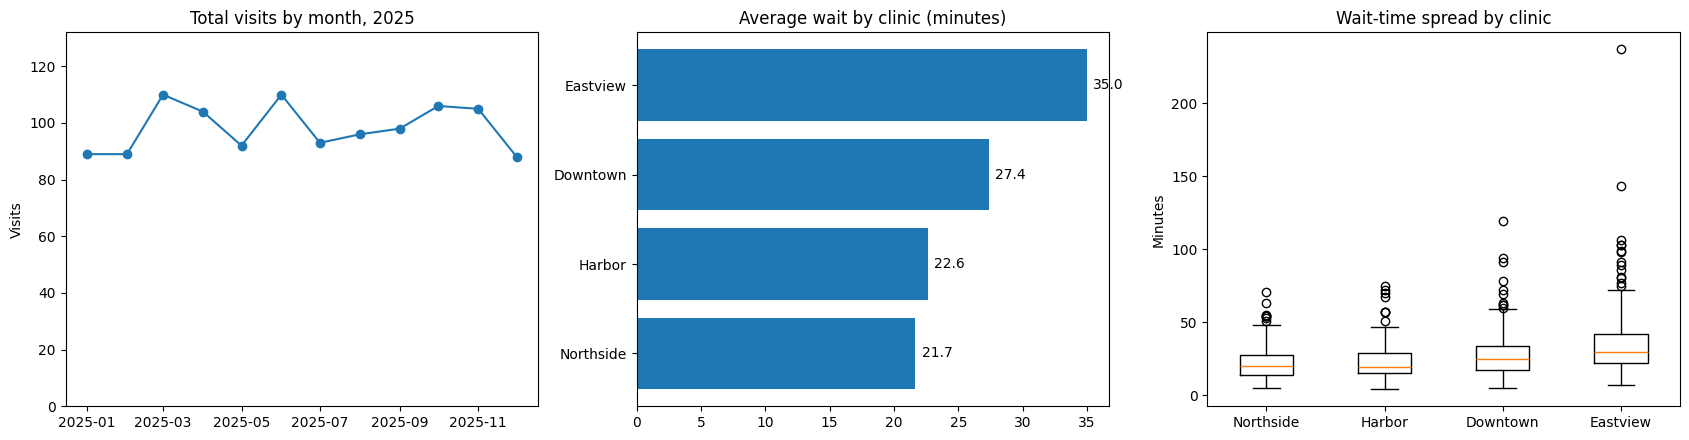

In [10]:
# 6.1 Three charts
df['month'] = pd.to_datetime(df['visit_date']).dt.to_period('M').dt.to_timestamp()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

monthly = df.groupby('month').size()
ax[0].plot(monthly.index, monthly.values, marker='o')
ax[0].set_title('Total visits by month, 2025'); ax[0].set_ylabel('Visits'); ax[0].set_ylim(0, monthly.max() * 1.2)

avg_wait = valid.groupby('clinic')['wait_min'].mean().sort_values()
ax[1].barh(avg_wait.index, avg_wait.values)
ax[1].set_title('Average wait by clinic (minutes)')
for i, v in enumerate(avg_wait.values): ax[1].text(v + 0.5, i, f'{v:.1f}', va='center')

order = avg_wait.index.tolist()
ax[2].boxplot([valid.loc[valid['clinic'] == c, 'wait_min'] for c in order])
ax[2].set_xticks(range(1, len(order) + 1)); ax[2].set_xticklabels(order)
ax[2].set_title('Wait-time spread by clinic'); ax[2].set_ylabel('Minutes')
plt.tight_layout(); plt.show()

**6.2 Spot the problem.** Run the cell below. It draws mean satisfaction by clinic twice. Explain what is misleading about the left chart and why the right one is better.

### How to solve it

Check any chart against four questions:

1. **Does the axis start at zero?** For bars, it must. The left chart starts just below the lowest bar, so differences of a fraction of a point look huge.
2. **Do the colors mean something?** Red and green imply good and bad, but no target is shown, and about 1 in 12 men can't tell them apart.
3. **Are the values labeled?** Without labels, the eye judges by bar height, which the axis has distorted.
4. **Would a manager make a different decision from this chart than from the data?** Here, yes: the left chart suggests a failing clinic; the real gap is under half a point.

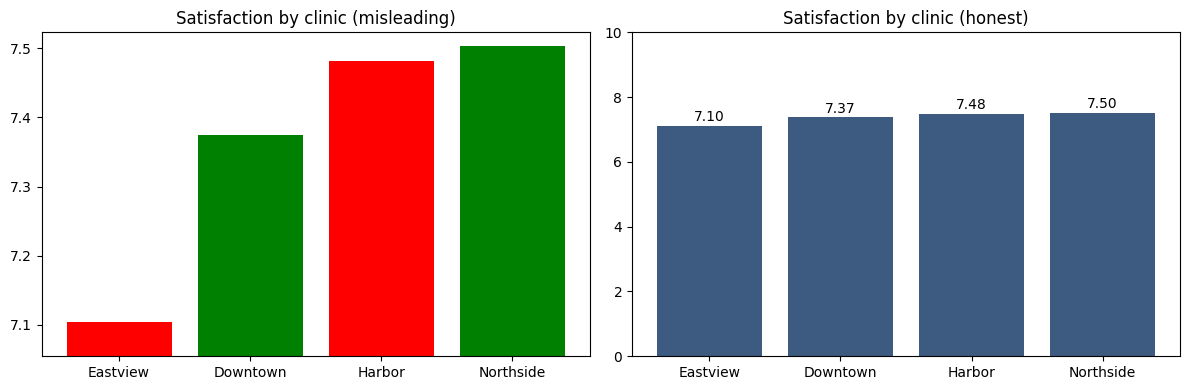

In [11]:
# 6.2 Misleading vs. honest chart (run as-is)
sat = df.groupby('clinic')['satisfaction'].mean().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(sat.index, sat.values, color=['red', 'green', 'red', 'green']); ax[0].set_ylim(sat.min() - 0.05, sat.max() + 0.02)
ax[0].set_title('Satisfaction by clinic (misleading)')
ax[1].bar(sat.index, sat.values, color='#3D5A80'); ax[1].set_ylim(0, 10)
for i, v in enumerate(sat.values): ax[1].text(i, v + 0.15, f'{v:.2f}', ha='center')
ax[1].set_title('Satisfaction by clinic (honest)')
plt.tight_layout(); plt.show()

**6.2 Model answer:** The left chart's y-axis starts just below the lowest bar, so differences of a fraction of a point look enormous; a manager might wrongly conclude one clinic is failing. Its red and green colors imply good and bad without any target and are hard to read for color-blind viewers. The right chart starts the axis at zero, uses one neutral color, and labels the values, so the small real differences are shown honestly.

**6.3 Model answer:** The fact table holds one row per visit with the measurable values (wait_min, charge, cost, satisfaction) and keys such as clinic, date, and payer. Dimension tables hold the descriptive attributes: Clinic (name, address, manager), Date (month, quarter, weekday), and Payer. Average wait should be a measure, because it must recalculate for whatever clinic, month, or payer the user filters; a calculated column is fixed row by row.

## Section 7: Decisions under uncertainty

**Scenario (public administration).** A city health department has budget for one new program: a **mobile health van**, **extended clinic hours**, or **neither** (status quo). The payoff depends on how many residents use the service. Net annual benefits, in \$ thousands:

| Decision | High uptake (p = 0.35) | Medium (p = 0.45) | Low (p = 0.20) |
| --- | --- | --- | --- |
| Mobile van | 420 | 150 | −180 |
| Extended hours | 220 | 140 | 40 |
| Status quo | 0 | 0 | 0 |

**7.1** Calculate the EMV of each option. Which does EMV recommend?

**7.2** Calculate the expected value with perfect information and the EVPI. What is the most the department should pay for a study that predicts uptake perfectly?

### How to solve it

**EMV** = sum of (probability × payoff) for each option.
- Van: 0.35 × 420 + 0.45 × 150 + 0.20 × (−180) = 147 + 67.5 − 36 = **178.5**
- Extended hours: 0.35 × 220 + 0.45 × 140 + 0.20 × 40 = 77 + 63 + 8 = **148.0**
- Status quo: **0**. Choose the highest EMV: the van.

**EVPI** is what knowing the future in advance would be worth.
1. For each state, take the best payoff: High → 420 (van), Medium → 150 (van), Low → 40 (hours).
2. Weight by the probabilities: 0.35 × 420 + 0.45 × 150 + 0.20 × 40 = **222.5** (EV with perfect information).
3. EVPI = EV with perfect information − best EMV = 222.5 − 178.5 = **44.0**, i.e. **\$44,000**.

**Reading it:** \$44,000 is the ceiling for any study. A real study is imperfect, so it is worth less.

**Common mistake:** subtracting the wrong EMV. Always use the best one.

In [12]:
# 7.1 and 7.2
p = np.array([0.35, 0.45, 0.20])
payoff = pd.DataFrame({'High': [420, 220, 0], 'Medium': [150, 140, 0], 'Low': [-180, 40, 0]},
                      index=['Mobile van', 'Extended hours', 'Status quo'])
emv = payoff.values @ p
for name, v in zip(payoff.index, emv): print(f"EMV {name}: {v:.1f}")
best = emv.max()
ev_pi = (payoff.max(axis=0).values * p).sum()
print(f"\nBest EMV = {best:.1f} ({payoff.index[emv.argmax()]})")
print(f"EV with perfect information = {ev_pi:.1f}")
print(f"EVPI = {ev_pi - best:.1f}  (i.e., ${(ev_pi - best) * 1000:,.0f})")

EMV Mobile van: 178.5
EMV Extended hours: 148.0
EMV Status quo: 0.0

Best EMV = 178.5 (Mobile van)
EV with perfect information = 222.5
EVPI = 44.0  (i.e., $44,000)


**7.1–7.2 Model answer:** The van has the highest EMV (\$178,500), ahead of extended hours (\$148,000). With perfect information the department would pick the van when uptake is high or medium and extended hours when it's low, for an expected \$222,500. EVPI = \$44,000, so no study, however accurate, is worth more than \$44,000.

**7.3 Bayes' rule.** A resident survey can signal "high interest." It does so 80% of the time when uptake will be high, 40% when medium, and 10% when low. If the survey signals high interest:

- Update the three probabilities.
- Recalculate the EMVs. Does the recommendation change?

### How to solve it

Bayes' rule updates a prior probability with new evidence.

1. **Joint probability** for each state = prior × P(signal given that state):
   High 0.35 × 0.80 = 0.28; Medium 0.45 × 0.40 = 0.18; Low 0.20 × 0.10 = 0.02.
2. **P(signal)** = sum of the joints = 0.28 + 0.18 + 0.02 = **0.48**.
3. **Posterior** = joint ÷ P(signal): High 0.28 ÷ 0.48 = **0.583**; Medium **0.375**; Low **0.042**.
4. **Re-run the EMVs** with the posterior probabilities instead of the priors. Van: 420 × 0.583 + 150 × 0.375 − 180 × 0.042 ≈ **293.8**.

**Tip:** set it up as a table with columns state, prior, likelihood, joint, posterior. That is exactly how to lay it out in Excel or on the exam.

In [13]:
# 7.3 Bayes update
likelihood = np.array([0.80, 0.40, 0.10])
joint = p * likelihood
p_signal = joint.sum()
posterior = joint / p_signal
print(f"P(high-interest signal) = {p_signal:.2f}")
for s, pr, po in zip(payoff.columns, p, posterior): print(f"  {s}: prior {pr:.2f} -> posterior {po:.4f}")
emv_post = payoff.values @ posterior
for name, v in zip(payoff.index, emv_post): print(f"EMV given signal, {name}: {v:.1f}")

P(high-interest signal) = 0.48
  High: prior 0.35 -> posterior 0.5833
  Medium: prior 0.45 -> posterior 0.3750
  Low: prior 0.20 -> posterior 0.0417
EMV given signal, Mobile van: 293.8
EMV given signal, Extended hours: 182.5
EMV given signal, Status quo: 0.0


**7.3 Model answer:** A high-interest signal raises the chance of high uptake from 35% to about 58% and cuts low uptake to about 4%. The van's EMV rises to about \$293,750, so the recommendation stays the same but with much more confidence.

**7.4 Expected utility.** The department is risk-averse. Use the utility function U(x) = 1 − exp(−x / 300), with x in \$ thousands. For the van and extended hours, calculate the expected utility and the certainty equivalent, CE = −300 × ln(1 − EU). Which option does a risk-averse department prefer, and what is the van's risk premium (EMV − CE)?

### How to solve it

**Idea.** A risk-averse decision-maker values a sure thing more than a gamble with the same average. A utility function captures that.

1. Convert each payoff to utility: U(x) = 1 − exp(−x ÷ 300). For example, U(420) = 1 − e^(−1.4) = 0.753, and U(−180) = 1 − e^(0.6) = −0.822.
2. **Expected utility (EU)** = sum of probability × utility, the same weighting as EMV but on utilities.
3. **Certainty equivalent (CE)** converts EU back into dollars: CE = −300 × ln(1 − EU). It is the sure amount the department would accept instead of the gamble.
4. **Risk premium** = EMV − CE: how much expected value the department gives up to avoid risk.

**Result:** the van's CE (about 97) is below extended hours' CE (about 141), so a risk-averse department prefers extended hours, even though the van's EMV is higher.

**Excel:** `=1-EXP(-x/300)` for utility and `=-300*LN(1-EU)` for CE.

In [14]:
# 7.4 Expected utility
R = 300
U = lambda x: 1 - np.exp(-np.asarray(x) / R)
for name in ['Mobile van', 'Extended hours']:
    eu = (U(payoff.loc[name].values) * p).sum()
    ce = -R * np.log(1 - eu)
    print(f"{name}: EMV {payoff.loc[name].values @ p:.1f}, EU {eu:.4f}, CE {ce:.1f}, risk premium {payoff.loc[name].values @ p - ce:.1f}")

Mobile van: EMV 178.5, EU 0.2763, CE 97.0, risk premium 81.5
Extended hours: EMV 148.0, EU 0.3747, CE 140.8, risk premium 7.2


**7.4 Model answer:** Once risk is priced in, extended hours has the higher certainty equivalent, so a risk-averse department prefers it (CE about \$140,800 vs. \$97,000 for the van) even though the van has the higher EMV. The van's risk premium of about \$81,500 reflects its chance of losing \$180,000.

**7.5 Monte Carlo.** Downtown is considering a larger facility. Annual visits are uncertain, roughly Normal(mean 9,000, SD 1,500); the margin per visit is uncertain, Uniform(\$55, \$75); and the added fixed cost is \$520,000 a year.

Simulate 10,000 years (use `np.random.default_rng(42)`). Report the mean and standard deviation of annual profit and the probability of a loss. Then rerun with 1,000 and 100,000 trials and describe what changes. [Excel: `NORM.INV(RAND(), …)` in a data table]

### How to solve it

**Idea.** When inputs are uncertain, simulate thousands of possible years and look at the distribution of results instead of a single estimate.

1. **Draw the inputs:** visits ~ Normal(9,000, 1,500); margin ~ Uniform(55, 75). Use a fixed seed (`default_rng(42)`) so the results can be reproduced.
2. **Calculate the outcome for every trial:** profit = visits × margin − 520,000.
3. **Summarize:** mean profit (expected outcome), SD (risk), and P(loss) = share of trials with profit < 0.
4. **Vary the number of trials:** the numbers barely change between 10,000 and 100,000. More trials make the estimate more stable (law of large numbers); they don't change the underlying risk.

**Excel:** `=NORM.INV(RAND(), 9000, 1500)` and `=55 + 20*RAND()` in columns; copy down 10,000 rows; then `AVERAGE`, `STDEV.S` and `COUNTIF(profit, "<0")/10000`.

  1,000 trials: mean $   62,885, SD $  110,430, P(loss) 0.284
 10,000 trials: mean $   64,606, SD $  111,313, P(loss) 0.286
100,000 trials: mean $   64,352, SD $  110,824, P(loss) 0.290


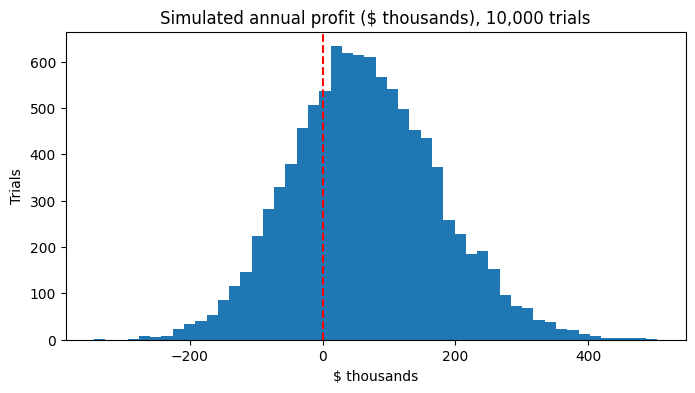

In [15]:
# 7.5 Monte Carlo
def simulate(n, seed=42):
    rng = np.random.default_rng(seed)
    visits = rng.normal(9000, 1500, n)
    margin = rng.uniform(55, 75, n)
    return visits * margin - 520000

for n in [1_000, 10_000, 100_000]:
    profit = simulate(n)
    print(f"{n:>7,} trials: mean ${profit.mean():>9,.0f}, SD ${profit.std():>9,.0f}, P(loss) {np.mean(profit < 0):.3f}")

profit = simulate(10_000)
plt.figure(figsize=(8, 4)); plt.hist(profit / 1000, bins=50)
plt.axvline(0, color='red', ls='--'); plt.title('Simulated annual profit ($ thousands), 10,000 trials')
plt.xlabel('$ thousands'); plt.ylabel('Trials'); plt.show()

**7.5 Model answer:** The expansion's average profit is positive, but the spread is wide and there is a substantial probability of a loss: about 29%, or more than one year in four. Average profit is about \$64,000 against a standard deviation of about \$111,000. More trials don't change the answer much; they make the estimates more stable (the law of large numbers). A risk-averse board might want to lower the fixed cost or phase the expansion before approving it.

## Wrap-up checklist

Before the midterm, make sure you can do each of these without notes:

- Classify a question as descriptive, diagnostic, predictive, or prescriptive.
- Calculate a newsvendor critical ratio and explain what it means.
- Name the right system (ERP, CRM, SCM, warehouse) and data type for a scenario.
- Spot and fix duplicates, inconsistent labels, text numbers, sentinel codes, missing values, and impossible dates.
- Calculate a rate, a median, an IQR fence, and a z-score, and say which measure fits which audience.
- Choose a chart for a question and explain why a chart is misleading.
- Calculate EMV, EVPI, a Bayes update, a certainty equivalent, and read a Monte Carlo result.